In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv("CC_Customer_Dataset.csv")
print(df.shape)
df.head()

(660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
# Sl_No and Customer Key are identifiers, so they are excluded
features = ["Avg_Credit_Limit", "Total_Credit_Cards", "Total_visits_bank",
            "Total_visits_online", "Total_calls_made"]
print(df[features].isna().sum())

X = StandardScaler().fit_transform(df[features])

Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


In [3]:
for k in range(2, 7):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    print(f"k={k} | Silhouette={silhouette_score(X, labels):.4f} | DBI={davies_bouldin_score(X, labels):.4f}")

k=2 | Silhouette=0.4177 | DBI=0.9326
k=3 | Silhouette=0.5148 | DBI=0.6810
k=4 | Silhouette=0.3481 | DBI=1.1493
k=5 | Silhouette=0.2569 | DBI=1.3851
k=6 | Silhouette=0.2268 | DBI=1.4109


In [4]:
K = 3
model = AgglomerativeClustering(n_clusters=K, linkage="ward")
df["Cluster"] = model.fit_predict(X)

print(df["Cluster"].value_counts().sort_index())
df.groupby("Cluster")[features].mean().round(2)

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
0,33851.95,5.52,3.49,0.98,1.99
1,12151.11,2.42,0.94,3.55,6.86
2,141040.00,8.74,0.60,10.90,1.08


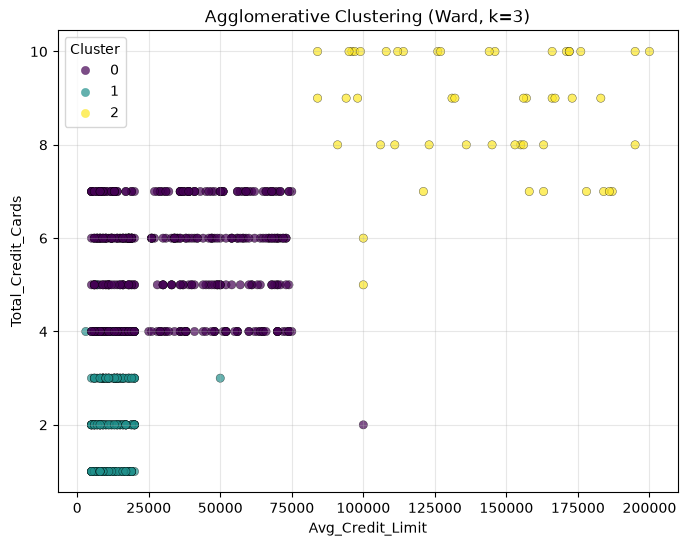

In [5]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(df["Avg_Credit_Limit"], df["Total_Credit_Cards"],
                 c=df["Cluster"], cmap="viridis", alpha=0.7,
                 edgecolor="k", linewidth=0.3)
plt.xlabel("Avg_Credit_Limit")
plt.ylabel("Total_Credit_Cards")
plt.title(f"Agglomerative Clustering (Ward, k={K})")
plt.legend(*sc.legend_elements(), title="Cluster")
plt.grid(alpha=0.3)
plt.show()

In [6]:
sil = silhouette_score(X, df["Cluster"])
dbi = davies_bouldin_score(X, df["Cluster"])
print(f"Silhouette Score      : {sil:.4f}  (higher is better)")
print(f"Davies-Bouldin Index  : {dbi:.4f}  (lower is better)")

Silhouette Score      : 0.5148  (higher is better)
Davies-Bouldin Index  : 0.6810  (lower is better)
